# AtliQ Grands: Revenue Leakage & Profitability Analysis

**Brief:** Consulting & Analytics Club, IIT Guwahati, Summer Projects '25:
*Optimizing Revenue Leakage & Profitability in the Hospitality Sector*.

**Data:** AtliQ Grands hotel chain, 25 properties in 4 cities, check-ins from 1 May to 31 Jul 2022 (92 days).

| File | Grain | Rows |
|---|---|---|
| `fact_bookings.csv` | one booking | 134,590 |
| `fact_aggregated_bookings.csv` | property × check-in date × room class | 9,200 |
| `dim_hotels.csv` | property | 25 |
| `dim_rooms.csv` | room class | 4 |
| `dim_date.csv` | calendar day | 92 |

**How this notebook is organised (it mirrors the brief):**
1. Data model & quality checks
2. KPI framework + headline KPIs + Week-on-Week (WoW)
3. Data analysis module: weekday vs weekend, room class, city, platform, occupancy vs revenue, spend segments
4. Root cause analysis: underperforming hotels, cancellations, pricing, "dip weeks"
5. Revenue leakage sizing
6. Consulting recommendations + business justification (ROI, payback, best/likely/worst)
7. WoW forecast for August 2022
8. Exports for the dashboard

Every number in the report and dashboard is produced by a cell below.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from pathlib import Path

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

ROOT = Path("..")
RAW = ROOT / "data" / "raw"
CHARTS = ROOT / "outputs" / "charts"
TABLES = ROOT / "outputs" / "tables"
DASH = ROOT / "outputs" / "dashboard_data"
for p in (CHARTS, TABLES, DASH):
    p.mkdir(parents=True, exist_ok=True)

# One consistent chart style
BLUE, RED, GREY, GREEN, AMBER = "#2F5D8A", "#C8443F", "#A0A8B3", "#3C8D5A", "#D98E04"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 170, "savefig.bbox": "tight",
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#E6E8EB", "grid.linewidth": 0.8, "axes.axisbelow": True,
})

def inr_m(v):
    """Format rupees as ₹ millions."""
    return f"₹{v/1e6:,.1f}M"

def save(fig, name):
    fig.savefig(CHARTS / name)
    plt.show()

## 1. Data model & quality checks

In [2]:
fb = pd.read_csv(RAW / "fact_bookings.csv", parse_dates=["booking_date", "check_in_date", "checkout_date"])
fa = pd.read_csv(RAW / "fact_aggregated_bookings.csv")
dim_date = pd.read_csv(RAW / "dim_date.csv")
dim_hotels = pd.read_csv(RAW / "dim_hotels.csv")
dim_rooms = pd.read_csv(RAW / "dim_rooms.csv")

# Clean the date dimension: parse dates, fix the "weekeday" typo, tidy column names
dim_date = dim_date.rename(columns={"mmm yy": "month", "week no": "week"})
dim_date["date"] = pd.to_datetime(dim_date["date"], format="%d-%b-%y")
dim_date["day_type"] = dim_date["day_type"].replace({"weekeday": "weekday"})
dim_date["dow"] = dim_date["date"].dt.day_name()
dim_date["week_num"] = dim_date["week"].str.replace("W ", "").astype(int)

fa["check_in_date"] = pd.to_datetime(fa["check_in_date"], format="%d-%b-%y")

print({n: len(d) for n, d in [("fact_bookings", fb), ("fact_aggregated", fa),
                              ("dim_date", dim_date), ("dim_hotels", dim_hotels), ("dim_rooms", dim_rooms)]})

{'fact_bookings': 134590, 'fact_aggregated': 9200, 'dim_date': 92, 'dim_hotels': 25, 'dim_rooms': 4}


In [3]:
# Quality checks. Each one drives a decision noted in the markdown cell that follows.
checks = {
    "duplicate booking_id": fb["booking_id"].duplicated().sum(),
    "duplicate aggregated keys": fa.duplicated(["property_id", "check_in_date", "room_category"]).sum(),
    "nulls in bookings (excl. ratings)": fb.drop(columns="ratings_given").isna().sum().sum(),
    "bookings with booking_date after check-in": (fb["booking_date"] > fb["check_in_date"]).sum(),
    "aggregated rows where bookings > capacity": (fa["successful_bookings"] > fa["capacity"]).sum(),
    "share of bookings with a rating": round(fb["ratings_given"].notna().mean(), 3),
    "hotels sharing the same name AND city": int(dim_hotels.duplicated(["property_name", "city"], keep=False).sum()),
}
for k, v in checks.items():
    print(f"{k:45s} {v}")
print(dim_hotels[dim_hotels.duplicated(["property_name", "city"], keep=False)])
print("Property-ID series by city (first digits):",
      dim_hotels.assign(series=dim_hotels["property_id"] // 1000).groupby("series")["city"].agg(lambda c: sorted(set(c))).to_dict())

duplicate booking_id                          0
duplicate aggregated keys                     0
nulls in bookings (excl. ratings)             0
bookings with booking_date after check-in     0
aggregated rows where bookings > capacity     0
share of bookings with a rating               0.421
hotels sharing the same name AND city         2
   property_id  property_name category    city
1        16559  Atliq Exotica   Luxury  Mumbai
7        17559  Atliq Exotica   Luxury  Mumbai
Property-ID series by city (first digits): {16: ['Delhi', 'Mumbai'], 17: ['Mumbai'], 18: ['Hyderabad'], 19: ['Bangalore']}


In [4]:
# Q1. Does `successful_bookings` exclude cancellations, as the name suggests?
per_key = fb.groupby(["property_id", "check_in_date", "room_category"]).size().rename("all_bookings")
recon = fa.set_index(["property_id", "check_in_date", "room_category"]).join(per_key)
print("successful_bookings == ALL bookings (incl. cancelled & no-show):",
      (recon["successful_bookings"] == recon["all_bookings"]).mean())

# Q2. How is revenue realised for each booking status?
fb["realised_ratio"] = fb["revenue_realized"] / fb["revenue_generated"]
print(fb.groupby("booking_status")["realised_ratio"].agg(["min", "max"]))

# Q3. Who leaves ratings?
print(fb.groupby("booking_status")["ratings_given"].apply(lambda s: s.notna().mean()).rename("rated share"))

successful_bookings == ALL bookings (incl. cancelled & no-show): 1.0
                min  max
booking_status          
Cancelled      0.40 0.40
Checked Out    1.00 1.00
No Show        1.00 1.00
booking_status
Cancelled     0.00
Checked Out   0.60
No Show       0.00
Name: rated share, dtype: float64


In [5]:
# Q4. How are prices set? Base price per (property, room class), then a surcharge per extra guest.
fb["base_price"] = fb.groupby(["property_id", "room_category"])["revenue_generated"].transform("min")
fb["price_multiple"] = (fb["revenue_generated"] / fb["base_price"]).round(2)
print(pd.crosstab(fb["no_guests"], fb["price_multiple"]))

# Q5. Does price change with lead time, day type or length of stay? (dynamic pricing / last-minute discounts)
fb["lead_days"] = (fb["check_in_date"] - fb["booking_date"]).dt.days
fb["nights"] = (fb["checkout_date"] - fb["check_in_date"]).dt.days
tmp = fb.merge(dim_date[["date", "day_type"]], left_on="check_in_date", right_on="date")
print("Price multiple by day type:", tmp.groupby("day_type")["price_multiple"].mean().round(3).to_dict())
print("Price multiple by lead-time bucket:",
      tmp.groupby(pd.cut(tmp["lead_days"], [-1, 0, 2, 6, 13, 30]), observed=True)["price_multiple"].mean().round(3).to_dict())
print("Avg booked revenue by nights:", fb.groupby("nights")["revenue_generated"].mean().round(0).to_dict())

price_multiple   1.00   1.10   1.20  1.30  1.40
no_guests                                      
1               44313      0      0     0     0
2               60223      0      0     0     0
3                   0  15122      0     0     0
4                   0      0  12096     0     0
5                   0      0      0  1391     0
6                   0      0      0     0  1445
Price multiple by day type: {'weekday': 1.037, 'weekend': 1.036}
Price multiple by lead-time bucket: {Interval(-1, 0, closed='right'): 1.032, Interval(0, 2, closed='right'): 1.036, Interval(2, 6, closed='right'): 1.039, Interval(6, 13, closed='right'): 1.04, Interval(13, 30, closed='right'): 1.037}
Avg booked revenue by nights: {1: 14955.0, 2: 14969.0, 3: 14953.0, 4: 14744.0, 5: 14779.0, 6: 14805.0}


**What the checks tell us (and the decisions they drive):**

- **Clean data:** no duplicates, no nulls outside ratings, no impossible dates, no overbooking.
- **Hotel master-data issue:** two different hotels (16559 and 17559) are both "Atliq Exotica, Mumbai".
  IDs starting 16xxx are otherwise all Delhi, so **16559 is probably a Delhi hotel mis-coded as Mumbai**.
  We keep the data as given, label hotels by ID, and flag that Mumbai's city totals may be overstated (16559 is the
  chain's top-revenue hotel).
- **`successful_bookings` counts every booking, including cancellations and no-shows.** So the standard
  "Occupancy %" is really *booked* occupancy. We also report **realised occupancy** (checked-out stays ÷ capacity).
- **Revenue rules:** a cancelled booking keeps **40%** of booked revenue, and a no-show is charged **100%**.
  So all revenue leakage comes from cancellations.
- **Ratings come only from checked-out guests, and only 60% of them rate.** Ratings are a sample, not a census.
- **Pricing is completely static.** Price = base rate for the property and room class, plus 10% per guest beyond two.
  It does not change by weekday/weekend, lead time or season. **There are no last-minute discounts.**
- **Data quirk:** booked revenue does not grow with length of stay (a 6-night stay costs the same as 1 night).
  We treat revenue as **per booking**, and ADR follows the dataset's standard definition (revenue ÷ bookings).
- **Not in the data** (asked for in the brief): ancillary services (spa, meals, transport), cancellation reasons,
  competitor prices, review text, costs. These are covered with clearly labelled assumptions or flagged as gaps.

## 2. KPI framework, headline KPIs and Week-on-Week

| KPI | Definition |
|---|---|
| Revenue | Σ revenue_realized |
| Booked revenue | Σ revenue_generated |
| Revenue leakage | Booked revenue − Revenue |
| Capacity (room-nights available) | Σ capacity |
| Occupancy % (booked) | Σ successful_bookings ÷ Σ capacity |
| Realised occupancy % | checked-out bookings ÷ Σ capacity |
| ADR | Revenue ÷ total bookings |
| RevPAR | Revenue ÷ capacity (= ADR × booked occupancy) |
| Cancellation % / No-show % | cancelled (no-show) ÷ total bookings |
| Realisation % | checked-out ÷ total bookings |
| DSRN / DBRN / DURN | capacity, bookings, checked-out per day |
| Average rating | mean rating from guests who rated |

In [6]:
# Join dimensions onto both fact tables
bk = (fb.merge(dim_hotels, on="property_id")
        .merge(dim_rooms, left_on="room_category", right_on="room_id")
        .merge(dim_date, left_on="check_in_date", right_on="date"))
ag = (fa.merge(dim_hotels, on="property_id")
        .merge(dim_rooms, left_on="room_category", right_on="room_id")
        .merge(dim_date, left_on="check_in_date", right_on="date"))

bk["is_cancelled"] = bk["booking_status"].eq("Cancelled")
bk["is_noshow"] = bk["booking_status"].eq("No Show")
bk["is_checkedout"] = bk["booking_status"].eq("Checked Out")
bk["leakage"] = bk["revenue_generated"] - bk["revenue_realized"]

def kpis(b, a):
    """All headline KPIs for a slice of bookings (b) and the matching capacity rows (a)."""
    days = a["date"].nunique()
    rev, booked = b["revenue_realized"].sum(), b["revenue_generated"].sum()
    n, cap, succ = len(b), a["capacity"].sum(), a["successful_bookings"].sum()
    return pd.Series({
        "revenue": rev,
        "booked_revenue": booked,
        "leakage": booked - rev,
        "leakage_pct": 100 * (booked - rev) / booked,
        "bookings": n,
        "capacity": cap,
        "occupancy_pct": 100 * succ / cap,
        "realised_occupancy_pct": 100 * b["is_checkedout"].sum() / cap,
        "adr": rev / n,
        "revpar": rev / cap,
        "cancellation_pct": 100 * b["is_cancelled"].mean(),
        "noshow_pct": 100 * b["is_noshow"].mean(),
        "realisation_pct": 100 * b["is_checkedout"].mean(),
        "avg_rating": b["ratings_given"].mean(),
        "dsrn": cap / days,
        "dbrn": n / days,
        "durn": b["is_checkedout"].sum() / days,
    })

overall = kpis(bk, ag)
overall.to_frame("value")

,value
revenue,"1,708,771,229.00"
booked_revenue,"2,007,546,215.00"
leakage,"298,774,986.00"
leakage_pct,14.88
bookings,"134,590.00"
capacity,"232,576.00"
occupancy_pct,57.87
realised_occupancy_pct,40.59
adr,"12,696.12"
revpar,"7,347.15"


In [7]:
# Week-on-Week. Weeks run Sunday–Saturday; W32 holds only 31 Jul, so it is excluded from WoW.
full_weeks = dim_date.groupby("week_num").size().loc[lambda s: s == 7].index
weekly = pd.DataFrame({w: kpis(bk[bk["week_num"] == w], ag[ag["week_num"] == w]) for w in full_weeks}).T
weekly.index.name = "week_num"

wow_cols = ["revenue", "occupancy_pct", "adr", "revpar", "realisation_pct", "dsrn"]
wow = weekly[wow_cols].pct_change() * 100
print("Last full week (W31) vs W30, % change:")
print(wow.iloc[-1].round(2))

Last full week (W31) vs W30, % change:
revenue            0.20
occupancy_pct      0.01
adr                0.19
revpar             0.20
realisation_pct   -0.03
dsrn               0.00
Name: 31, dtype: float64


## 3. Data analysis module

In [8]:
# 3a. Weekday vs weekend (dim_date defines the weekend as Saturday + Sunday)
by_daytype = pd.DataFrame({d: kpis(bk[bk["day_type"] == d], ag[ag["day_type"] == d])
                           for d in ["weekday", "weekend"]}).T
by_daytype["capacity_share_pct"] = 100 * by_daytype["capacity"] / by_daytype["capacity"].sum()
by_daytype[["revenue", "capacity_share_pct", "occupancy_pct", "realised_occupancy_pct", "adr", "revpar", "cancellation_pct"]]

,revenue,capacity_share_pct,occupancy_pct,realised_occupancy_pct,adr,revpar,cancellation_pct
weekday,"1,069,703,782.00",70.65,51.34,35.92,"12,679.47","6,509.88",25.04
weekend,"639,067,447.00",29.35,73.58,51.85,"12,724.09","9,362.80",24.48


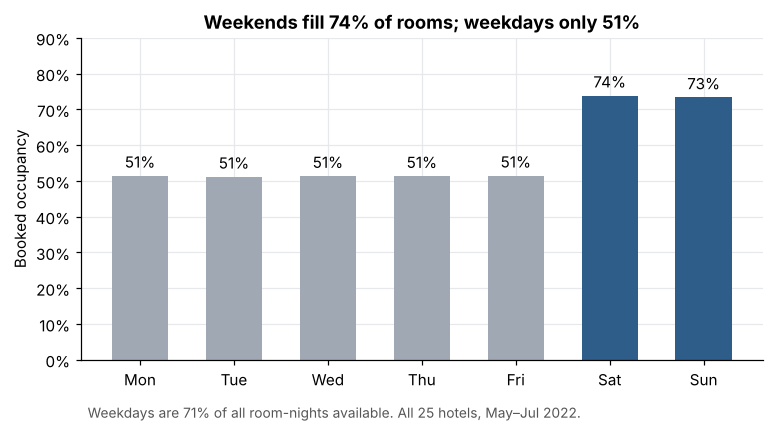

In [9]:
dow_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
occ_dow = (ag.groupby("dow")[["successful_bookings", "capacity"]].sum()
             .pipe(lambda d: 100 * d["successful_bookings"] / d["capacity"]).reindex(dow_order))

fig, ax = plt.subplots(figsize=(8, 3.8))
colors = [BLUE if d in ("Saturday", "Sunday") else GREY for d in dow_order]
bars = ax.bar([d[:3] for d in dow_order], occ_dow.values, color=colors, width=0.6)
ax.bar_label(bars, fmt="%.0f%%", padding=3)
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_ylim(0, 90)
ax.set_title(f"Weekends fill {by_daytype.loc['weekend','occupancy_pct']:.0f}% of rooms; weekdays only {by_daytype.loc['weekday','occupancy_pct']:.0f}%")
ax.set_ylabel("Booked occupancy")
ax.text(0.01, -0.18, f"Weekdays are {by_daytype.loc['weekday','capacity_share_pct']:.0f}% of all room-nights available. All 25 hotels, May–Jul 2022.",
        transform=ax.transAxes, color="#555", fontsize=9)
save(fig, "02_occupancy_by_weekday.png")

In [10]:
# 3b. Room class, city and hotel category
by_room = pd.DataFrame({r: kpis(bk[bk["room_class"] == r], ag[ag["room_class"] == r])
                        for r in ["Standard", "Elite", "Premium", "Presidential"]}).T
by_room["revenue_share_pct"] = 100 * by_room["revenue"] / by_room["revenue"].sum()
by_room["booking_share_pct"] = 100 * by_room["bookings"] / by_room["bookings"].sum()

by_city = pd.DataFrame({c: kpis(bk[bk["city"] == c], ag[ag["city"] == c])
                        for c in bk["city"].unique()}).T.sort_values("revenue", ascending=False)
by_city["revenue_share_pct"] = 100 * by_city["revenue"] / by_city["revenue"].sum()

by_category = pd.DataFrame({c: kpis(bk[bk["category"] == c], ag[ag["category"] == c])
                            for c in ["Luxury", "Business"]}).T

show = ["revenue", "revenue_share_pct", "occupancy_pct", "adr", "revpar", "cancellation_pct", "avg_rating"]
display(by_room[show + ["booking_share_pct"]], by_city[show], by_category[show[:1] + show[2:]])

,revenue,revenue_share_pct,occupancy_pct,adr,revpar,cancellation_pct,avg_rating,booking_share_pct
Standard,"309,580,895.00",18.12,57.88,"8,052.36","4,660.68",24.79,3.63,28.57
Elite,"560,271,204.00",32.79,57.61,"11,317.47","6,520.24",24.96,3.60,36.78
Premium,"462,166,344.00",27.05,57.58,"15,120.28","8,706.32",24.88,3.59,22.71
Presidential,"376,752,786.00",22.05,59.22,"23,440.10","13,881.83",24.44,3.69,11.94


,revenue,revenue_share_pct,occupancy_pct,adr,revpar,cancellation_pct,avg_rating
Mumbai,"668,640,991.00",39.13,57.88,"15,386.97","8,906.66",24.75,3.65
Bangalore,"420,397,050.00",24.60,55.77,"13,130.84","7,322.97",24.99,3.41
Hyderabad,"325,232,870.00",19.03,58.07,"9,322.20","5,413.69",24.63,3.66
Delhi,"294,500,318.00",17.23,60.55,"12,153.87","7,358.83",25.06,3.78


,revenue,occupancy_pct,adr,revpar,cancellation_pct,avg_rating
Luxury,"1,052,751,932.00",57.66,"12,583.70","7,256.15",24.71,3.62
Business,"656,019,297.00",58.21,"12,880.80","7,498.05",25.03,3.61


In [11]:
# 3c. Booking platforms (share of bookings and revenue). No commission data, so net revenue cannot be computed.
by_platform = (bk.groupby("booking_platform")
                 .agg(bookings=("booking_id", "size"), revenue=("revenue_realized", "sum"),
                      cancellation_pct=("is_cancelled", "mean"), avg_rating=("ratings_given", "mean"))
                 .sort_values("bookings", ascending=False))
by_platform["booking_share_pct"] = 100 * by_platform["bookings"] / by_platform["bookings"].sum()
by_platform["cancellation_pct"] *= 100
by_platform["channel"] = np.where(by_platform.index.str.startswith("direct"), "Direct", "Third-party")
print("Direct share of bookings:", round(by_platform.loc[by_platform["channel"] == "Direct", "booking_share_pct"].sum(), 1), "%")
by_platform

Direct share of bookings: 15.0 %


,bookings,revenue,cancellation_pct,avg_rating,booking_share_pct,channel
booking_platform,,,,,,
others,55066,699353302,24.88,3.62,40.91,Third-party
makeyourtrip,26898,340834504,24.99,3.62,19.99,Third-party
logtrip,14756,187554488,24.30,3.62,10.96,Third-party
direct online,13379,169026467,24.99,3.61,9.94,Direct
tripster,9630,123066801,24.99,3.62,7.16,Third-party
journey,8106,102531334,24.78,3.63,6.02,Third-party
direct offline,6755,86404333,24.49,3.62,5.02,Direct


In [12]:
# 3d. Occupancy vs revenue: does filling rooms drive revenue? (daily, all hotels)
daily = pd.DataFrame({d: kpis(bk[bk["date"] == d], ag[ag["date"] == d]) for d in dim_date["date"]}).T
daily.index.name = "date"
daily = daily.join(dim_date.set_index("date")[["day_type", "week_num", "month"]])
r_daily = daily["occupancy_pct"].corr(daily["revenue"])
print(f"Correlation of daily occupancy with daily revenue: r = {r_daily:.3f}")
print("Std-dev of daily ADR:", round(daily["adr"].std(), 0), "vs mean", round(daily["adr"].mean(), 0))
print("Monthly view (May–Jul is the only season in the data):")
by_month = pd.DataFrame({m: kpis(bk[bk["month"] == m], ag[ag["month"] == m])
                         for m in ["May 22", "Jun 22", "Jul 22"]}).T
by_month[["revenue", "occupancy_pct", "adr", "revpar", "cancellation_pct"]]

Correlation of daily occupancy with daily revenue: r = 0.999
Std-dev of daily ADR: 109.0 vs mean 12694.0
Monthly view (May–Jul is the only season in the data):


,revenue,occupancy_pct,adr,revpar,cancellation_pct
May 22,"581,930,666.00",58.55,"12,683.20","7,425.62",24.95
Jun 22,"553,932,355.00",57.60,"12,680.73","7,303.96",25.09
Jul 22,"572,908,208.00",57.45,"12,724.22","7,310.49",24.46


Revenue moves almost one-for-one with occupancy because **ADR barely moves** (static pricing).
With only May–July in the data, we can't test true seasonality (festive season, winter). The months are flat.

In [13]:
# 3e. Customer segmentation by spending behaviour.
# No guest ID exists, so segments are built on the booking: booked spend per booking.
bins = [0, 10_000, 15_000, 25_000, np.inf]
labels = ["Budget (<₹10k)", "Mid (₹10–15k)", "Upper (₹15–25k)", "Top (₹25k+)"]
bk["spend_segment"] = pd.cut(bk["revenue_generated"], bins=bins, labels=labels, right=False)

segments = (bk.groupby("spend_segment", observed=True)
              .agg(bookings=("booking_id", "size"), revenue=("revenue_realized", "sum"),
                   avg_booked_spend=("revenue_generated", "mean"), avg_guests=("no_guests", "mean"),
                   weekend_share=("day_type", lambda s: (s == "weekend").mean()),
                   cancellation_pct=("is_cancelled", "mean"), avg_rating=("ratings_given", "mean"),
                   top_room=("room_class", lambda s: s.mode()[0])))
segments["booking_share_pct"] = 100 * segments["bookings"] / segments["bookings"].sum()
segments["revenue_share_pct"] = 100 * segments["revenue"] / segments["revenue"].sum()
segments["cancellation_pct"] *= 100
segments["weekend_share"] *= 100
segments

,bookings,revenue,avg_booked_spend,avg_guests,weekend_share,cancellation_pct,avg_rating,top_room,booking_share_pct,revenue_share_pct
spend_segment,,,,,,,,,,
Budget (<₹10k),33980,247059380,"8,551.89",1.75,37.37,24.97,3.63,Standard,25.25,14.46
Mid (₹10–15k),42172,442509585,"12,326.31",2.06,37.33,24.77,3.61,Elite,31.33,25.90
Upper (₹15–25k),46727,710910246,"17,879.00",2.14,37.36,24.83,3.59,Premium,34.72,41.60
Top (₹25k+),11711,308292018,"30,885.13",2.39,36.97,24.65,3.74,Presidential,8.70,18.04


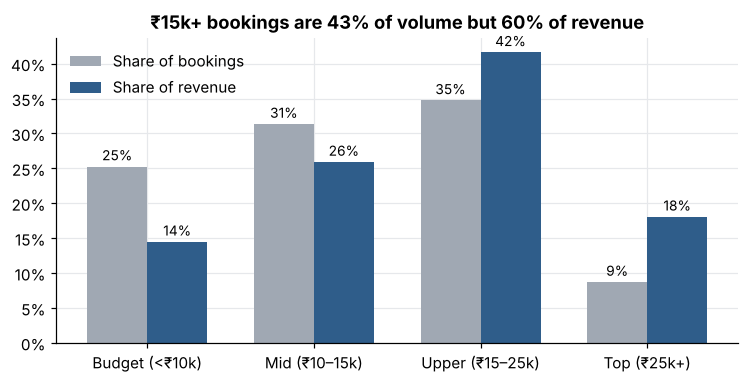

In [14]:
fig, ax = plt.subplots(figsize=(8, 3.6))
x = np.arange(len(segments))
b1 = ax.bar(x - 0.18, segments["booking_share_pct"], 0.36, color=GREY, label="Share of bookings")
b2 = ax.bar(x + 0.18, segments["revenue_share_pct"], 0.36, color=BLUE, label="Share of revenue")
ax.bar_label(b1, fmt="%.0f%%", padding=2, fontsize=9)
ax.bar_label(b2, fmt="%.0f%%", padding=2, fontsize=9)
ax.set_xticks(x, segments.index)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
top = segments.iloc[-1]; upper = segments.iloc[-2]
ax.set_title(f"₹15k+ bookings are {top['booking_share_pct'] + upper['booking_share_pct']:.0f}% of volume "
             f"but {top['revenue_share_pct'] + upper['revenue_share_pct']:.0f}% of revenue")
ax.legend(frameon=False, loc="upper left")
save(fig, "06_spend_segments.png")

## 4. Root cause analysis

In [15]:
# 4a. Hotel-level scorecard and performance tiers
prop = pd.DataFrame({pid: kpis(bk[bk["property_id"] == pid], ag[ag["property_id"] == pid])
                     for pid in dim_hotels["property_id"]}).T
prop.index.name = "property_id"
prop = dim_hotels.set_index("property_id").join(prop)
prop["hotel"] = prop["property_name"] + ", " + prop["city"] + " (" + prop.index.astype(str) + ")"

# Occupancy falls into three clear bands; label them
prop["tier"] = pd.cut(prop["occupancy_pct"], [0, 50, 60, 100], labels=["Low", "Mid", "High"])
tier_summary = prop.groupby("tier", observed=True).agg(
    hotels=("hotel", "size"), occupancy_pct=("occupancy_pct", "mean"), avg_rating=("avg_rating", "mean"),
    revpar=("revpar", "mean"), revenue=("revenue", "sum"), capacity=("capacity", "sum"))
print(tier_summary)
print("Correlation across hotels: rating vs occupancy r =", round(prop["avg_rating"].corr(prop["occupancy_pct"]), 3))
print("Low-tier hotels:", prop.loc[prop["tier"] == "Low", "hotel"].tolist())

      hotels  occupancy_pct  avg_rating   revpar        revenue   capacity
tier                                                                      
Low        4          44.62        2.34 5,951.77 220,378,013.00  38,180.00
Mid        9          53.44        3.05 6,584.18 566,764,821.00  85,376.00
High      12          65.98        4.28 8,465.43 921,628,395.00 109,020.00
Correlation across hotels: rating vs occupancy r = 0.998
Low-tier hotels: ['Atliq Bay, Mumbai (17562)', 'Atliq Exotica, Hyderabad (18559)', 'Atliq Grands, Bangalore (19558)', 'Atliq Seasons, Mumbai (17564)']


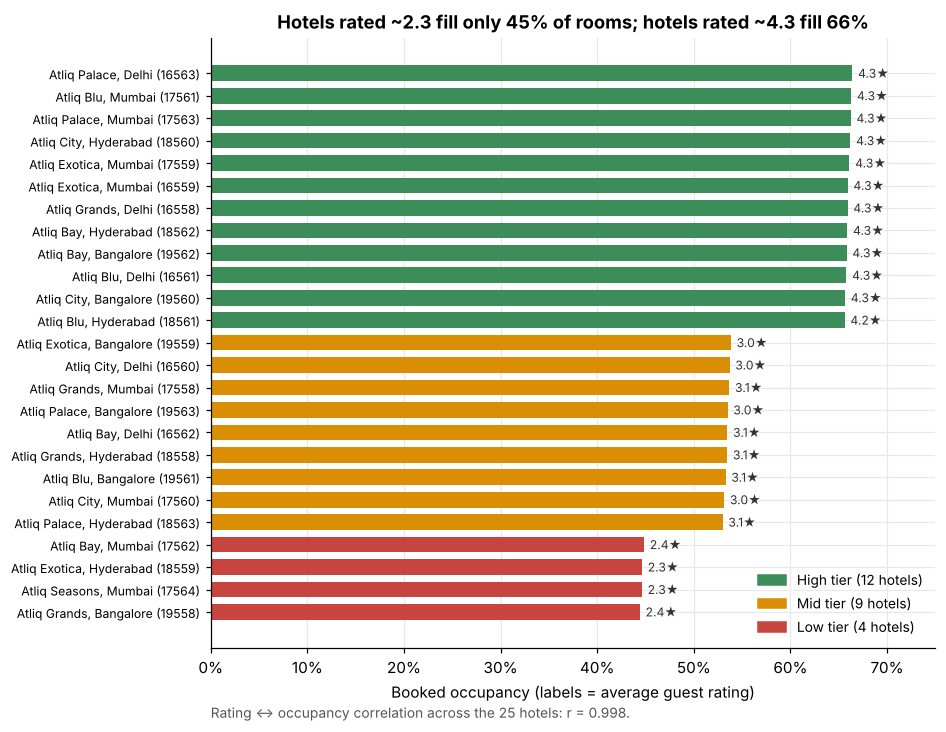

In [16]:
ranked = prop.sort_values("occupancy_pct")
fig, ax = plt.subplots(figsize=(8.5, 7.2))
tier_colors = {"Low": RED, "Mid": AMBER, "High": GREEN}
bars = ax.barh(ranked["hotel"], ranked["occupancy_pct"], color=ranked["tier"].map(tier_colors).tolist(), height=0.7)
for b, rating in zip(bars, ranked["avg_rating"]):
    ax.text(b.get_width() + 0.6, b.get_y() + b.get_height() / 2, f"{rating:.1f}★", va="center", fontsize=8, color="#333")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_xlim(0, 75)
ax.tick_params(axis="y", labelsize=8)
ax.set_xlabel("Booked occupancy (labels = average guest rating)")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=tier_colors[t], label=f"{t} tier ({(prop['tier'] == t).sum()} hotels)") for t in ["High", "Mid", "Low"]],
          frameon=False, loc="lower right", fontsize=9)
ax.set_title(f"Hotels rated ~{tier_summary.loc['Low','avg_rating']:.1f} fill only {tier_summary.loc['Low','occupancy_pct']:.0f}% of rooms; "
             f"hotels rated ~{tier_summary.loc['High','avg_rating']:.1f} fill {tier_summary.loc['High','occupancy_pct']:.0f}%")
ax.text(0.0, -0.115, f"Rating ↔ occupancy correlation across the 25 hotels: r = {prop['avg_rating'].corr(prop['occupancy_pct']):.3f}.",
        transform=ax.transAxes, color="#555", fontsize=9)
save(fig, "03_property_rating_vs_occupancy.png")

In [17]:
# 4b. Cancellations: is any segment driving them?
bk["lead_bucket"] = pd.cut(bk["lead_days"], [-1, 0, 2, 6, 13, 30],
                           labels=["Same day", "1–2 days", "3–6 days", "7–13 days", "14+ days"])
drivers = {
    "Platform": bk.groupby("booking_platform")["is_cancelled"].mean(),
    "Lead time": bk.groupby("lead_bucket", observed=True)["is_cancelled"].mean(),
    "Room class": bk.groupby("room_class")["is_cancelled"].mean(),
    "City": bk.groupby("city")["is_cancelled"].mean(),
    "Day type": bk.groupby("day_type")["is_cancelled"].mean(),
    "Guests": bk.groupby("no_guests")["is_cancelled"].mean(),
}
spread = pd.DataFrame({k: {"min_pct": 100 * v.min(), "max_pct": 100 * v.max(), "range_pts": 100 * (v.max() - v.min())}
                       for k, v in drivers.items()}).T
spread

,min_pct,max_pct,range_pts
Platform,24.30,24.99,0.69
Lead time,23.82,24.90,1.08
Room class,24.44,24.96,0.52
City,24.63,25.06,0.43
Day type,24.48,25.04,0.55
Guests,23.87,26.09,2.22


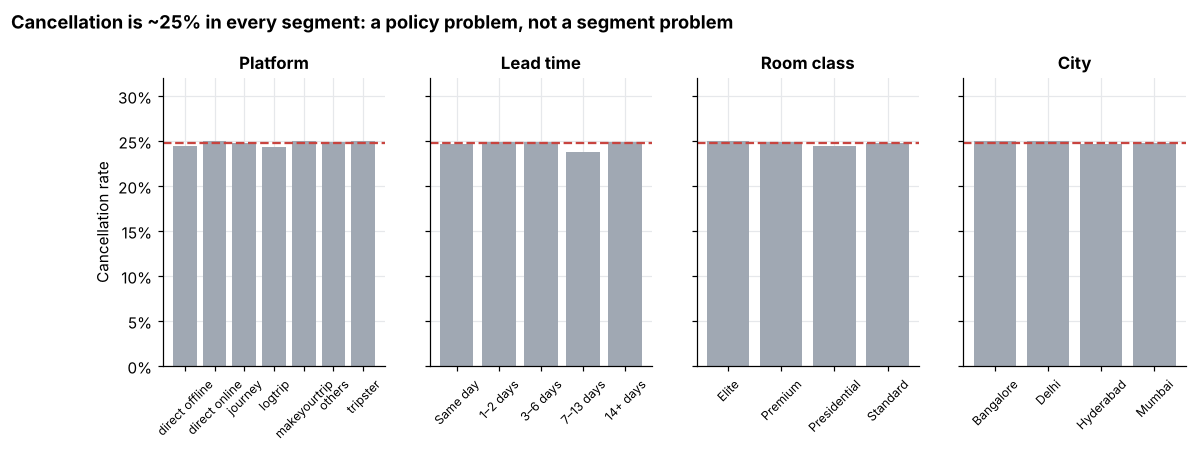

In [18]:
fig, axes = plt.subplots(1, 4, figsize=(12, 3.4), sharey=True)
for ax, key in zip(axes, ["Platform", "Lead time", "Room class", "City"]):
    s = drivers[key] * 100
    ax.bar([str(i) for i in s.index], s.values, color=GREY)
    ax.axhline(overall["cancellation_pct"], color=RED, lw=1.5, ls="--")
    ax.set_title(key, fontsize=11)
    ax.tick_params(axis="x", rotation=45, labelsize=8)
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
    ax.set_ylim(0, 32)
axes[0].set_ylabel("Cancellation rate")
fig.suptitle(f"Cancellation is ~{overall['cancellation_pct']:.0f}% in every segment: a policy problem, not a segment problem",
             fontweight="bold", x=0.01, ha="left", y=1.06)
save(fig, "05_cancellation_uniformity.png")

**Root causes found:**

1. **Cancellations are uniform (~25%) everywhere**: across platform, lead time, room, city, day type and party size
   (range under 3 points). No segment to target, so the fix is **policy**: refund terms, deposits, reminders.
2. **Weekday under-utilisation:** weekdays hold 71% of room-nights, yet occupancy is 51% vs 74% at weekends,
   and **prices are identical**. No weekday product or discount fills the gap, and no weekend premium monetises demand.
3. **Four low-rated hotels** (ratings ~2.3) run at ~45% occupancy, against 53% (rating ~3.0) and 66% (rating ~4.3).
   The link is very strong, though correlation alone doesn't prove the rating *causes* low occupancy.
4. **"Dip weeks"** (below): in 5 of 13 full weeks, occupancy drops ~10 points on every day of the week.
   The data gives no reason (no events or competitor data), so these need investigating.

In [19]:
# 4c. Dip weeks
weekly["is_dip"] = weekly["occupancy_pct"] < 56
dips = weekly.groupby("is_dip").agg(weeks=("revenue", "size"), avg_revenue=("revenue", "mean"),
                                    avg_occupancy=("occupancy_pct", "mean"))
print(dips)
print("Dip weeks:", list(weekly.index[weekly["is_dip"]]))
dip_gap = dips.loc[False, "avg_revenue"] - dips.loc[True, "avg_revenue"]
print("Revenue lost per dip week vs a normal week:", inr_m(dip_gap))

# Is the dip chain-wide or local?
ag_w = ag[ag["week_num"].isin(full_weeks)].copy()
ag_w["is_dip"] = ag_w["week_num"].map(weekly["is_dip"])
dip_by_city = (ag_w.groupby(["city", "is_dip"])[["successful_bookings", "capacity"]].sum()
                 .pipe(lambda d: 100 * d["successful_bookings"] / d["capacity"]).unstack())
dip_by_city

        weeks    avg_revenue  avg_occupancy
is_dip                                     
False       8 139,158,028.75          61.98
True        5 114,899,327.60          51.07
Dip weeks: [21, 23, 26, 30, 31]
Revenue lost per dip week vs a normal week: ₹24.3M


is_dip,False,True
city,,
Bangalore,59.69,49.26
Delhi,64.76,53.54
Hyderabad,62.27,51.12
Mumbai,62.03,51.10


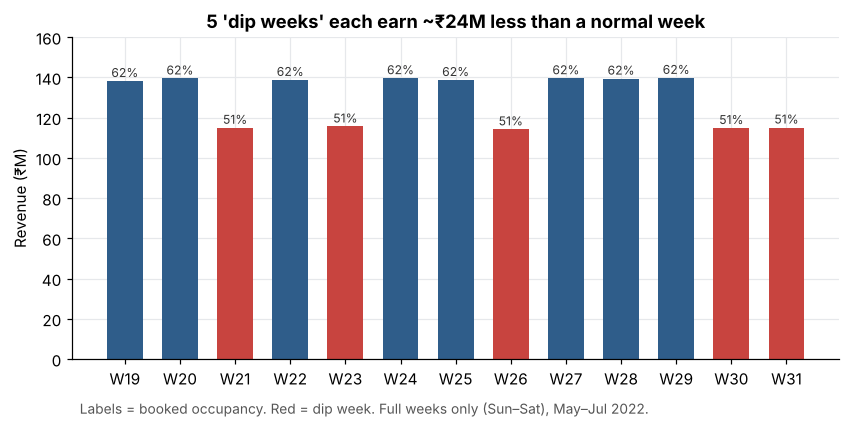

In [20]:
fig, ax = plt.subplots(figsize=(9, 3.8))
colors = [RED if d else BLUE for d in weekly["is_dip"]]
bars = ax.bar([f"W{w}" for w in weekly.index], weekly["revenue"] / 1e6, color=colors, width=0.65)
ax.set_ylabel("Revenue (₹M)")
ax.set_ylim(0, 160)
ax.set_title(f"{int(weekly['is_dip'].sum())} 'dip weeks' each earn ~₹{dip_gap/1e6:.0f}M less than a normal week")
for b, occ in zip(bars, weekly["occupancy_pct"]):
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 2, f"{occ:.0f}%", ha="center", fontsize=8, color="#333")
ax.text(0.01, -0.17, "Labels = booked occupancy. Red = dip week. Full weeks only (Sun–Sat), May–Jul 2022.",
        transform=ax.transAxes, color="#555", fontsize=9)
save(fig, "04_weekly_revenue_dips.png")

## 5. Revenue leakage sizing

In [21]:
cancel_loss = bk.loc[bk["is_cancelled"], "leakage"].sum()
noshow_loss = bk.loc[bk["is_noshow"], "leakage"].sum()

# Opportunity view: what would close each gap be worth? (realised revenue per booking held at today's level)
realised_per_booking = overall["revenue"] / overall["bookings"]
wkday = by_daytype.loc["weekday"]
weekday_gap_rooms = wkday["capacity"] * (by_daytype.loc["weekend", "occupancy_pct"] - wkday["occupancy_pct"]) / 100

low, mid = tier_summary.loc["Low"], tier_summary.loc["Mid"]
low_gap_rooms = low["capacity"] * (mid["occupancy_pct"] - low["occupancy_pct"]) / 100
low_rev_per_booking = bk.loc[bk["property_id"].isin(prop.index[prop["tier"] == "Low"]), "revenue_realized"].mean()

leakage = pd.DataFrame([
    ["Cancellations (60% of booked value refunded)", "Lost (realised)", cancel_loss],
    ["No-shows (charged in full)", "Lost (realised)", noshow_loss],
    ["Dip weeks vs normal weeks (5 weeks)", "Opportunity", dip_gap * dips.loc[True, "weeks"]],
    ["Weekday rooms if filled to weekend level", "Opportunity (ceiling)", weekday_gap_rooms * realised_per_booking],
    ["Low-tier hotels lifted to mid-tier occupancy", "Opportunity", low_gap_rooms * low_rev_per_booking],
], columns=["source", "type", "amount"])
leakage["pct_of_booked_revenue"] = 100 * leakage["amount"] / overall["booked_revenue"]
leakage["pct_of_realised_revenue"] = 100 * leakage["amount"] / overall["revenue"]
print("Booked:", inr_m(overall["booked_revenue"]), "| Realised:", inr_m(overall["revenue"]),
      "| Leakage:", inr_m(overall["leakage"]), f"({overall['leakage_pct']:.2f}% of booked)")
leakage

Booked: ₹2,007.5M | Realised: ₹1,708.8M | Leakage: ₹298.8M (14.88% of booked)


,source,type,amount,pct_of_booked_revenue,pct_of_realised_revenue
0,Cancellations (60% of booked value refunded),Lost (realised),"298,774,986.00",14.88,17.48
1,No-shows (charged in full),Lost (realised),0.00,0.00,0.00
2,Dip weeks vs normal weeks (5 weeks),Opportunity,"121,293,505.75",6.04,7.10
3,Weekday rooms if filled to weekend level,Opportunity (ceiling),"464,005,686.86",23.11,27.15
4,Low-tier hotels lifted to mid-tier occupancy,Opportunity,"43,570,901.18",2.17,2.55


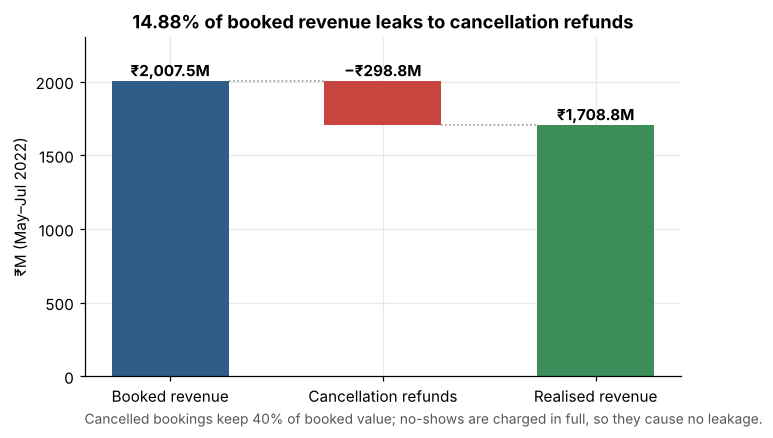

In [22]:
# Revenue leakage bridge: booked → realised (no-shows are charged in full, so they add no step)
fig, ax = plt.subplots(figsize=(7, 4))
steps = [("Booked revenue", overall["booked_revenue"], BLUE, 0),
         ("Cancellation refunds", -cancel_loss, RED, overall["revenue"]),
         ("Realised revenue", overall["revenue"], GREEN, 0)]
for i, (lab, val, col, bottom) in enumerate(steps):
    h = abs(val)
    ax.bar(i, h / 1e6, bottom=bottom / 1e6, color=col, width=0.55)
    txt = inr_m(val) if val >= 0 else f"−{inr_m(-val)}"
    ax.text(i, (bottom + h) / 1e6 + 30, txt, ha="center", fontsize=10, fontweight="bold")
ax.plot([0.275, 0.725], [overall["booked_revenue"] / 1e6] * 2, color="#888", lw=1, ls=":")
ax.plot([1.275, 1.725], [overall["revenue"] / 1e6] * 2, color="#888", lw=1, ls=":")
ax.set_xticks(range(3), [s_[0] for s_ in steps])
ax.set_ylabel("₹M (May–Jul 2022)")
ax.set_ylim(0, 2300)
ax.set_title(f"{overall['leakage_pct']:.2f}% of booked revenue leaks to cancellation refunds")
ax.text(0.0, -0.14, "Cancelled bookings keep 40% of booked value; no-shows are charged in full, so they cause no leakage.",
        transform=ax.transAxes, color="#555", fontsize=9)
save(fig, "01_revenue_leakage_bridge.png")

## 6. Consulting recommendations & business justification

Four levers, each tied to a root cause. **All costs, rates and margins below are assumptions** (the dataset has
no cost data). They sit in one table so they can be replaced with real figures. Results are quarterly
(the 92 days in the data) and annualised ×(365/92), **assuming the quarter is representative**.

| Lever | Root cause | Mechanism |
|---|---|---|
| L1 Cancellation recovery | Uniform 25% cancellation, 60% refunded | Re-confirmation 72h before arrival, deposit on third-party bookings, waitlist resale of cancelled rooms. Some guests are put off by the deposit (booking friction). |
| L2 Weekday corporate & co-working packages | Weekday occupancy 51% | Corporate-stay contracts and day-use co-working in Mid/High-tier hotels, sold at 15% below rack rate |
| L3 Weekend dynamic pricing | Weekend occupancy 74% at the same price | Weekend rate premium, with some volume loss (price elasticity −0.6) |
| L4 Low-tier hotel turnaround | 4 hotels rated ~2.3 at 45% occupancy | Service-recovery programme (staff training, room fixes, review response) |

In [23]:
ASSUMPTIONS = {
    # scenario levers: (worst, likely, best)
    "L1_cancel_rate_cut_pts": (2.0, 3.0, 5.0),        # cancellation rate reduction, percentage points
    "L1_booking_friction_pct": (1.0, 0.5, 0.25),      # bookings lost because of the deposit, % of all bookings
    "L2_weekday_occ_lift_pts": (2.0, 4.0, 6.0),       # weekday booked-occupancy lift in Mid/High hotels
    "L2_package_discount": 0.15,                      # package price vs rack rate
    "L3_weekend_price_rise": (0.03, 0.05, 0.08),      # weekend rate premium
    "L3_price_elasticity": -0.6,                      # % volume change per % price change
    "L4_low_tier_occ_lift_pts": (2.0, 4.0, 8.0),      # best case ≈ closing the gap to mid tier
    # economics
    "contribution_margin": 0.70,                      # share of incremental room revenue kept after variable costs
    # one-time ₹: L1 CRM + automation; L2 co-working fit-out ₹0.5M × 21 Mid/High hotels; L3 revenue-management system;
    # L4 ₹6M per low-tier hotel (room fixes, training, review management)
    "one_time_cost": {"L1": 5.0e6, "L2": 10.5e6, "L3": 3.0e6, "L4": 24.0e6},
    # monthly ₹: L1 re-confirmation desk; L2 corporate sales team + marketing; L3 licence; L4 quality audits
    "monthly_cost":  {"L1": 1.5e6, "L2": 2.5e6, "L3": 0.5e6, "L4": 1.0e6},
}
ANNUALISE = 365 / 92
SCEN = ["Worst", "Likely", "Best"]
A = ASSUMPTIONS

# Baseline inputs from the data
realisation_ratio = overall["revenue"] / overall["booked_revenue"]              # realised ÷ booked, overall
avg_booked_cancelled = bk.loc[bk["is_cancelled"], "revenue_generated"].mean()
low_ids = prop.index[prop["tier"] == "Low"]
nonlow = bk[~bk["property_id"].isin(low_ids)]
nonlow_ag = ag[~ag["property_id"].isin(low_ids)]
cap_weekday_nonlow = nonlow_ag.loc[nonlow_ag["day_type"] == "weekday", "capacity"].sum()
booked_per_booking_weekday_nonlow = nonlow.loc[nonlow["day_type"] == "weekday", "revenue_generated"].mean()
weekend_revenue = by_daytype.loc["weekend", "revenue"]
cap_low = low["capacity"]

def lever_gains(i):
    """Quarterly incremental realised revenue per lever for scenario index i (0 worst, 1 likely, 2 best)."""
    recovered = A["L1_cancel_rate_cut_pts"][i] / 100 * overall["bookings"] * avg_booked_cancelled * 0.60
    friction = A["L1_booking_friction_pct"][i] / 100 * overall["bookings"] * realised_per_booking
    l1 = recovered - friction
    l2 = (cap_weekday_nonlow * A["L2_weekday_occ_lift_pts"][i] / 100
          * booked_per_booking_weekday_nonlow * (1 - A["L2_package_discount"]) * realisation_ratio)
    p = A["L3_weekend_price_rise"][i]
    l3 = weekend_revenue * ((1 + p) * (1 + A["L3_price_elasticity"] * p) - 1)
    l4 = cap_low * A["L4_low_tier_occ_lift_pts"][i] / 100 * low_rev_per_booking
    return {"L1": l1, "L2": l2, "L3": l3, "L4": l4}

rows = []
for i, s in enumerate(SCEN):
    for lever, q in lever_gains(i).items():
        annual_rev = q * ANNUALISE
        annual_contrib = annual_rev * A["contribution_margin"]
        one_time, monthly = A["one_time_cost"][lever], A["monthly_cost"][lever]
        annual_cost = monthly * 12
        net_monthly = annual_contrib / 12 - monthly
        rows.append({
            "scenario": s, "lever": lever,
            "quarterly_revenue_gain": q,
            "revpar_uplift_pct": 100 * q / overall["revenue"],      # same capacity, so ΔRevPAR% = ΔRevenue%
            "annual_revenue_gain": annual_rev,
            "annual_contribution": annual_contrib,
            "one_time_cost": one_time, "annual_running_cost": annual_cost,
            "year1_net_benefit": annual_contrib - annual_cost - one_time,
            "year1_roi_pct": 100 * (annual_contrib - annual_cost - one_time) / (one_time + annual_cost),
            "payback_months": one_time / net_monthly if net_monthly > 0 else np.nan,
        })
scenarios = pd.DataFrame(rows)
lever_names = {"L1": "Cancellation recovery", "L2": "Weekday corporate packages",
               "L3": "Weekend dynamic pricing", "L4": "Low-tier hotel turnaround"}
scenarios["lever_name"] = scenarios["lever"].map(lever_names)

scenario_totals = scenarios.groupby("scenario").agg(
    quarterly_revenue_gain=("quarterly_revenue_gain", "sum"), revpar_uplift_pct=("revpar_uplift_pct", "sum"),
    annual_revenue_gain=("annual_revenue_gain", "sum"), year1_net_benefit=("year1_net_benefit", "sum"),
    one_time_cost=("one_time_cost", "sum"), annual_running_cost=("annual_running_cost", "sum"),
    annual_contribution=("annual_contribution", "sum")).reindex(SCEN)
scenario_totals["year1_roi_pct"] = 100 * scenario_totals["year1_net_benefit"] / (
    scenario_totals["one_time_cost"] + scenario_totals["annual_running_cost"])
scenario_totals["new_revpar"] = overall["revpar"] * (1 + scenario_totals["revpar_uplift_pct"] / 100)
display(scenarios[scenarios["scenario"] == "Likely"].set_index("lever_name").drop(columns=["scenario", "lever"]))
scenario_totals

,quarterly_revenue_gain,revpar_uplift_pct,annual_revenue_gain,annual_contribution,one_time_cost,annual_running_cost,year1_net_benefit,year1_roi_pct,payback_months
lever_name,,,,,,,,,
Cancellation recovery,"27,553,204.33",1.61,"109,314,343.25","76,520,040.28","5,000,000.00","18,000,000.00","53,520,040.28",232.70,1.03
Weekday corporate packages,"59,150,213.59",3.46,"234,672,043.04","164,270,430.13","10,500,000.00","30,000,000.00","123,770,430.13",305.61,0.94
Weekend dynamic pricing,"11,822,747.77",0.69,"46,905,466.69","32,833,826.69","3,000,000.00","6,000,000.00","23,833,826.69",264.82,1.34
Low-tier hotel turnaround,"19,759,367.20",1.16,"78,393,141.59","54,875,199.12","24,000,000.00","12,000,000.00","18,875,199.12",52.43,6.72


,quarterly_revenue_gain,revpar_uplift_pct,annual_revenue_gain,year1_net_benefit,one_time_cost,annual_running_cost,annual_contribution,year1_roi_pct,new_revpar
scenario,,,,,,,,,
Worst,"53,755,498.03",3.15,"213,269,095.43","40,788,366.80","42,500,000.00","66,000,000.00","149,288,366.80",37.59,"7,578.28"
Likely,"118,285,532.88",6.92,"469,284,994.58","219,999,496.20","42,500,000.00","66,000,000.00","328,499,496.20",202.76,"7,855.74"
Best,"202,130,033.46",11.83,"801,928,937.10","452,850,255.97","42,500,000.00","66,000,000.00","561,350,255.97",417.37,"8,216.24"


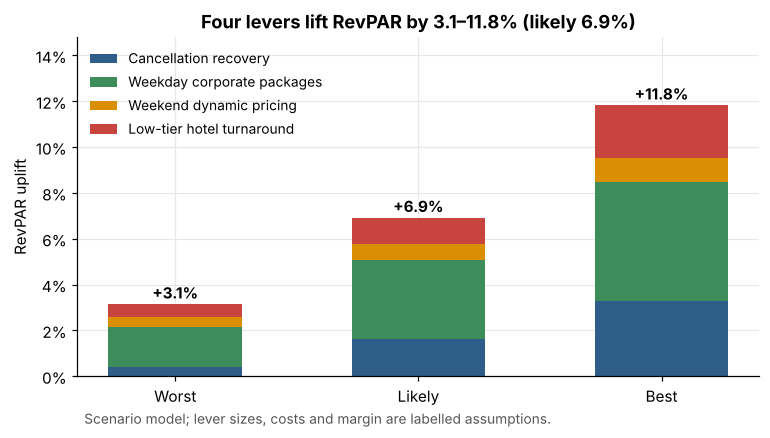

In [24]:
fig, ax = plt.subplots(figsize=(8, 4))
lever_colors = {"L1": BLUE, "L2": GREEN, "L3": AMBER, "L4": RED}
bottom = np.zeros(3)
for lev in ["L1", "L2", "L3", "L4"]:
    vals = scenarios[scenarios["lever"] == lev].set_index("scenario").reindex(SCEN)["revpar_uplift_pct"].values
    ax.bar(SCEN, vals, bottom=bottom, color=lever_colors[lev], width=0.55, label=lever_names[lev])
    bottom += vals
for i, tot in enumerate(bottom):
    ax.text(i, tot + 0.25, f"+{tot:.1f}%", ha="center", fontweight="bold")
ax.set_ylabel("RevPAR uplift")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_ylim(0, bottom.max() * 1.25)
ax.set_title("Four levers lift RevPAR by " + f"{bottom[0]:.1f}–{bottom[2]:.1f}% (likely {bottom[1]:.1f}%)")
ax.legend(frameon=False, fontsize=9, loc="upper left")
ax.text(0.01, -0.14, "Scenario model; lever sizes, costs and margin are labelled assumptions.",
        transform=ax.transAxes, color="#555", fontsize=9)
save(fig, "07_scenario_revpar_uplift.png")

## 7. Week-on-Week forecast for August 2022

We compare three simple forecasting methods with a walk-forward backtest over W21–W31,
forecasting each week using only earlier weeks:
- **Naive WoW**: next week = last week
- **4-week moving average**
- **Two-state model**: weeks are either "normal" or "dip". Forecast = probability-weighted average of the
  two levels seen so far.

In [25]:
rev = weekly["revenue"]
bt = []
for t in range(2, len(rev)):        # need at least 2 past weeks
    past = rev.iloc[:t]
    naive = past.iloc[-1]
    ma4 = past.iloc[-4:].mean()
    is_dip_past = weekly["is_dip"].iloc[:t]
    if is_dip_past.any() and (~is_dip_past).any():
        p_dip = is_dip_past.mean()
        two_state = p_dip * past[is_dip_past].mean() + (1 - p_dip) * past[~is_dip_past].mean()
    else:
        two_state = past.mean()
    bt.append({"week_num": rev.index[t], "actual": rev.iloc[t], "naive_wow": naive, "ma4": ma4, "two_state": two_state})
bt = pd.DataFrame(bt).set_index("week_num")
mape = {m: 100 * (abs(bt[m] - bt["actual"]) / bt["actual"]).mean() for m in ["naive_wow", "ma4", "two_state"]}
print("Backtest MAPE (W21–W31):", {k: round(v, 1) for k, v in mape.items()})

Backtest MAPE (W21–W31): {'naive_wow': np.float64(12.6), 'ma4': np.float64(11.4), 'two_state': np.float64(10.7)}


In [26]:
# Forecast W32–W35 (August). W32 is known to start as a dip week: 31 Jul (its Sunday) ran at dip-level occupancy.
p_dip = weekly["is_dip"].mean()
normal_lvl = weekly.loc[~weekly["is_dip"], "revenue"].mean()
dip_lvl = weekly.loc[weekly["is_dip"], "revenue"].mean()
expected = p_dip * dip_lvl + (1 - p_dip) * normal_lvl

sun = daily[(daily.index.dayofweek == 6)]
print("31 Jul occupancy:", round(daily.loc["2022-07-31", "occupancy_pct"], 1),
      "| normal-week Sundays:", round(sun[sun["week_num"].map(weekly["is_dip"]).eq(False)]["occupancy_pct"].mean(), 1),
      "| dip-week Sundays:", round(sun[sun["week_num"].map(weekly["is_dip"]).eq(True)]["occupancy_pct"].mean(), 1))

forecast = pd.DataFrame({
    "week": ["W32 (31 Jul–6 Aug)", "W33", "W34", "W35"],
    "forecast_revenue": [dip_lvl, expected, expected, expected],
    "low": [dip_lvl, dip_lvl, dip_lvl, dip_lvl],
    "high": [dip_lvl, normal_lvl, normal_lvl, normal_lvl],
    "basis": ["Dip week (31 Jul already ran at dip level)", "Probability-weighted", "Probability-weighted", "Probability-weighted"],
})
print(f"P(dip week) = {p_dip:.2f}; normal week {inr_m(normal_lvl)}, dip week {inr_m(dip_lvl)}, expected {inr_m(expected)}")
forecast

31 Jul occupancy: 65.3 | normal-week Sundays: 79.3 | dip-week Sundays: 65.4
P(dip week) = 0.38; normal week ₹139.2M, dip week ₹114.9M, expected ₹129.8M


,week,forecast_revenue,low,high,basis
0,W32 (31 Jul–6 Aug),"114,899,327.60","114,899,327.60","114,899,327.60",Dip week (31 Jul already ran at dip level)
1,W33,"129,827,759.08","114,899,327.60","139,158,028.75",Probability-weighted
2,W34,"129,827,759.08","114,899,327.60","139,158,028.75",Probability-weighted
3,W35,"129,827,759.08","114,899,327.60","139,158,028.75",Probability-weighted


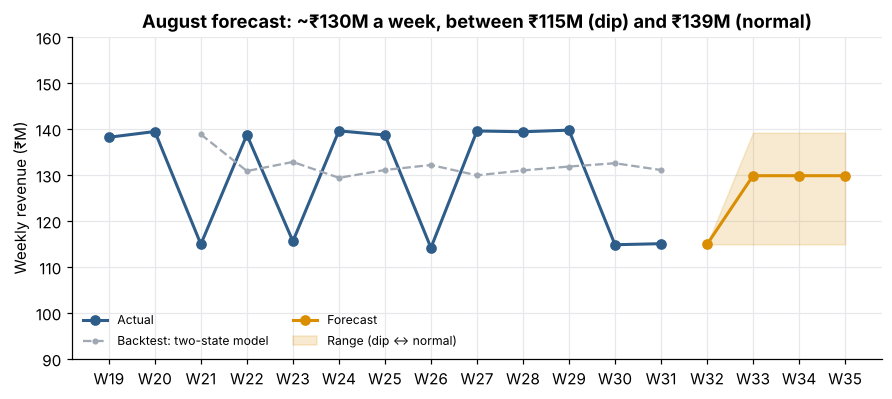

In [27]:
fig, ax = plt.subplots(figsize=(9.5, 3.8))
wk_labels = [f"W{w}" for w in weekly.index]
ax.plot(wk_labels, weekly["revenue"] / 1e6, color=BLUE, marker="o", lw=2, label="Actual")
ax.plot([f"W{w}" for w in bt.index], bt["two_state"] / 1e6, color=GREY, ls="--", marker=".", label="Backtest: two-state model")
f_x = ["W32", "W33", "W34", "W35"]
ax.plot(f_x, forecast["forecast_revenue"] / 1e6, color=AMBER, marker="o", lw=2, label="Forecast")
ax.fill_between(f_x, forecast["low"] / 1e6, forecast["high"] / 1e6, color=AMBER, alpha=0.18, label="Range (dip ↔ normal)")
ax.set_ylabel("Weekly revenue (₹M)")
ax.set_ylim(90, 160)
ax.set_title(f"August forecast: ~₹{expected/1e6:.0f}M a week, between ₹{dip_lvl/1e6:.0f}M (dip) and ₹{normal_lvl/1e6:.0f}M (normal)")
ax.legend(frameon=False, fontsize=8, ncol=2, loc="lower left")
save(fig, "08_forecast.png")

## 8. Exports (tables + dashboard data)

In [28]:
def out(df, name, folder=TABLES, index=True):
    df.to_csv(folder / f"{name}.csv", index=index)

out(overall.to_frame("value"), "kpi_overall")
out(weekly, "kpi_weekly"); out(wow, "kpi_wow")
out(by_daytype, "kpi_by_daytype"); out(by_room, "kpi_by_room_class"); out(by_city, "kpi_by_city")
out(by_category, "kpi_by_category"); out(by_platform, "kpi_by_platform"); out(by_month, "kpi_by_month")
out(segments, "spend_segments"); out(prop, "kpi_by_property"); out(tier_summary, "property_tiers")
out(spread, "cancellation_driver_spread"); out(leakage, "leakage_sizing", index=False)
out(scenarios, "scenario_by_lever", index=False); out(scenario_totals, "scenario_totals")
out(bt, "forecast_backtest"); out(forecast, "forecast_august", index=False)
out(pd.Series({k: str(v) for k, v in ASSUMPTIONS.items()}).to_frame("value"), "assumptions")

# Dashboard data: tidy, rounded, one file per visual
r = lambda d, n=2: d.round(n)
k = overall
wk_last, wk_prev = weekly.iloc[-1], weekly.iloc[-2]
dash_kpi = pd.DataFrame([{
    "revenue": round(k["revenue"]), "booked_revenue": round(k["booked_revenue"]), "leakage": round(k["leakage"]),
    "leakage_pct": round(k["leakage_pct"], 2), "revpar": round(k["revpar"], 0), "adr": round(k["adr"], 0),
    "occupancy_pct": round(k["occupancy_pct"], 2), "realised_occupancy_pct": round(k["realised_occupancy_pct"], 2),
    "cancellation_pct": round(k["cancellation_pct"], 2), "realisation_pct": round(k["realisation_pct"], 2),
    "avg_rating": round(k["avg_rating"], 2), "bookings": int(k["bookings"]),
    "revenue_wow_pct": round(wow.iloc[-1]["revenue"], 2), "revpar_wow_pct": round(wow.iloc[-1]["revpar"], 2),
    "occupancy_wow_pct": round(wow.iloc[-1]["occupancy_pct"], 2), "adr_wow_pct": round(wow.iloc[-1]["adr"], 2),
    "realisation_wow_pct": round(wow.iloc[-1]["realisation_pct"], 2),
}])
out(dash_kpi, "kpi_summary", DASH, index=False)

dash_weekly = weekly.reset_index()[["week_num", "revenue", "occupancy_pct", "realised_occupancy_pct", "adr", "revpar",
                                    "cancellation_pct", "is_dip"]]
dash_weekly["week"] = "W" + dash_weekly["week_num"].astype(str)
week_start = dim_date.groupby("week_num")["date"].min()
dash_weekly["week_start"] = dash_weekly["week_num"].map(week_start).dt.strftime("%Y-%m-%d")
out(r(dash_weekly.drop(columns="week_num")), "weekly_trend", DASH, index=False)

dash_daily = daily.reset_index()[["date", "day_type", "revenue", "occupancy_pct", "revpar"]]
dash_daily["date"] = pd.to_datetime(dash_daily["date"]).dt.strftime("%Y-%m-%d")
out(r(dash_daily), "daily_trend", DASH, index=False)

dash_prop = prop.reset_index()[["property_id", "property_name", "city", "category", "tier", "revenue", "occupancy_pct",
                                "adr", "revpar", "cancellation_pct", "avg_rating"]].sort_values("revpar", ascending=False)
out(r(dash_prop), "property_scorecard", DASH, index=False)
out(r(by_city.reset_index(names="city")[["city", "revenue", "revenue_share_pct", "occupancy_pct", "adr", "revpar", "cancellation_pct", "avg_rating"]]),
    "city_scorecard", DASH, index=False)
out(r(by_room.reset_index(names="room_class")[["room_class", "revenue", "revenue_share_pct", "booking_share_pct", "occupancy_pct", "adr", "revpar"]]),
    "room_class_split", DASH, index=False)
out(r(by_platform.reset_index()[["booking_platform", "channel", "bookings", "booking_share_pct", "revenue", "cancellation_pct"]]),
    "platform_split", DASH, index=False)
out(r(by_daytype.reset_index(names="day_type")[["day_type", "revenue", "capacity_share_pct", "occupancy_pct", "realised_occupancy_pct", "adr", "revpar"]]),
    "daytype_split", DASH, index=False)
out(r(occ_dow.rename("occupancy_pct").reset_index().rename(columns={"dow": "day"})), "occupancy_by_dow", DASH, index=False)
out(r(scenarios[["scenario", "lever", "lever_name", "quarterly_revenue_gain", "revpar_uplift_pct", "annual_revenue_gain",
                 "one_time_cost", "year1_net_benefit", "year1_roi_pct", "payback_months"]]), "scenario_by_lever", DASH, index=False)
out(r(scenario_totals.reset_index()), "scenario_totals", DASH, index=False)
out(r(forecast), "forecast_august", DASH, index=False)
print("Exported:", sorted(p.name for p in DASH.glob("*.csv")))

Exported: ['city_scorecard.csv', 'daily_trend.csv', 'daytype_split.csv', 'forecast_august.csv', 'kpi_summary.csv', 'occupancy_by_dow.csv', 'platform_split.csv', 'property_scorecard.csv', 'room_class_split.csv', 'scenario_by_lever.csv', 'scenario_totals.csv', 'weekly_trend.csv']
